In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
from scipy.special import logsumexp
from scipy.optimize import linear_sum_assignment
from scipy.stats import multivariate_normal
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.precision', 3)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

STATES = ['Normal', 'Suspicious', 'Attack']
K = len(STATES)
STATE_COLORS = ['#2e7d32', '#f9a825', '#c62828']
SEED = 42
rng = np.random.default_rng(SEED)

## 0. Dataset: sequential network-traffic windows




In [2]:
FEATURES = ['pkt_rate', 'avg_pkt_size', 'uniq_dst_ports', 'failed_conn_ratio', 'syn_ratio']
WIN_PER_DAY = 288                     # 5-minute windows
T_SESSION = 2 * WIN_PER_DAY           # 2 days per session

# Ground-truth generator parameters (unknown to the models)
A_TRUE = np.array([[0.970, 0.025, 0.005],
                   [0.080, 0.860, 0.060],
                   [0.040, 0.060, 0.900]])
PI_TRUE = np.array([0.90, 0.08, 0.02])

def emit(profile, diurnal, rng):
    if profile == 0:      # normal business traffic
        rate = 800 * diurnal * rng.lognormal(0, 0.15); size = rng.normal(750, 80)
        ports = rng.poisson(15);  fail = rng.beta(2, 40);  syn = rng.beta(3, 30)
    elif profile == 1:    # reconnaissance / scanning
        rate = 1100 * diurnal * rng.lognormal(0, 0.25); size = rng.normal(450, 120)
        ports = rng.poisson(180); fail = rng.beta(6, 14);  syn = rng.beta(8, 12)
    else:                 # volumetric attack (SYN flood / DDoS)
        rate = 5000 * rng.lognormal(0, 0.35); size = rng.normal(120, 40)
        ports = rng.poisson(40);  fail = rng.beta(12, 8);  syn = rng.beta(16, 4)
    return [rate, max(size, 60.0), ports, fail, syn]

def simulate_session(T, rng):
    z = np.empty(T, dtype=int)
    z[0] = rng.choice(K, p=PI_TRUE)
    for n in range(1, T):
        z[n] = rng.choice(K, p=A_TRUE[z[n - 1]])
    t = np.arange(T)
    diurnal = 1 + 0.45 * np.sin(2 * np.pi * t / WIN_PER_DAY + rng.uniform(0, 2 * np.pi))
    rows = []
    for n in range(T):
        prof = z[n]
        if z[n] == 1 and rng.random() < 0.30: prof = 0   # stealthy scan
        if z[n] == 2 and rng.random() < 0.20: prof = 1   # pulsing attack
        rows.append(emit(prof, diurnal[n], rng))
    df = pd.DataFrame(rows, columns=FEATURES)
    df['state'] = z
    return df

train_sessions = [simulate_session(T_SESSION, rng) for _ in range(30)]
test_sessions  = [simulate_session(T_SESSION, rng) for _ in range(10)]

all_train = pd.concat(train_sessions, ignore_index=True)
print(f"Train: {len(train_sessions)} sessions x {T_SESSION} windows = {len(all_train)} windows")
print(f"Test : {len(test_sessions)} sessions x {T_SESSION} windows = {len(test_sessions) * T_SESSION} windows\n")
print("State distribution (train):")
print(all_train['state'].map(dict(enumerate(STATES))).value_counts(normalize=True).round(3))
all_train.groupby(all_train['state'].map(dict(enumerate(STATES))))[FEATURES].mean()

NameError: name 'np' is not defined

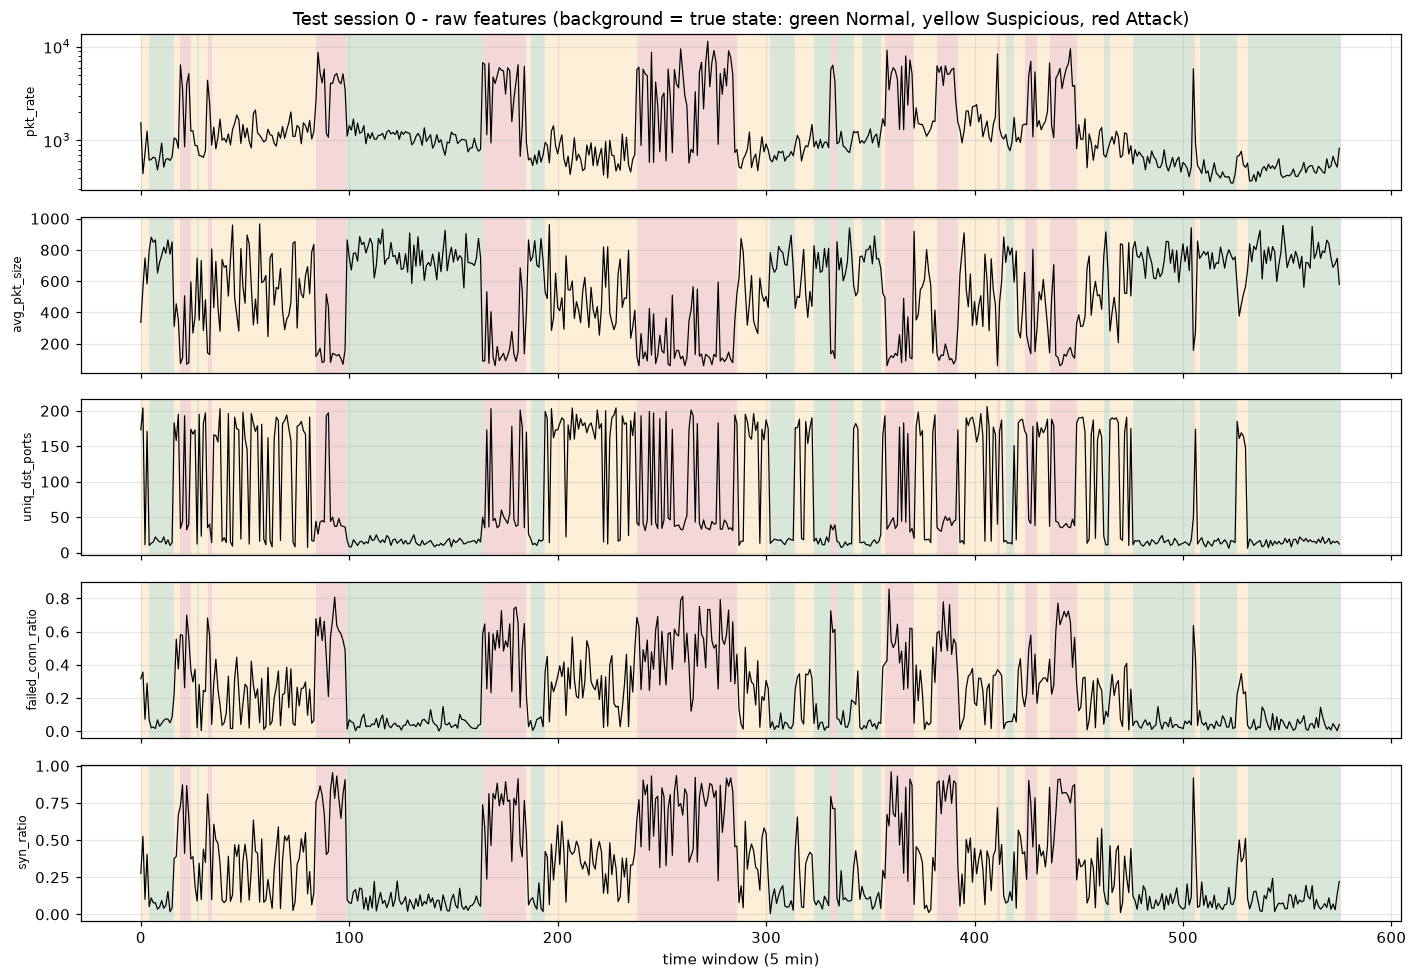

In [ ]:
def shade_states(ax, z, alpha=0.18):
    # shade background of a time-series plot by (true) hidden state
    start = 0
    for n in range(1, len(z) + 1):
        if n == len(z) or z[n] != z[start]:
            ax.axvspan(start, n, color=STATE_COLORS[z[start]], alpha=alpha, lw=0)
            start = n

s0 = test_sessions[0]
fig, axes = plt.subplots(5, 1, figsize=(13, 9), sharex=True)
for ax, f in zip(axes, FEATURES):
    ax.plot(s0[f].values, lw=0.8, color='k')
    shade_states(ax, s0['state'].values)
    ax.set_ylabel(f, fontsize=8)
axes[0].set_yscale('log')
axes[0].set_title('Test session 0 - raw features (background = true state: green Normal, yellow Suspicious, red Attack)')
axes[-1].set_xlabel('time window (5 min)')
plt.tight_layout(); plt.show()

## 1. Sequential feature preparation and a Markov model of traffic conditions


In [4]:
def featurize(df):
    eps = 1e-4
    logit = lambda p: np.log(np.clip(p, eps, 1 - eps) / (1 - np.clip(p, eps, 1 - eps)))
    return np.column_stack([
        np.log(df['pkt_rate']),
        np.log(df['avg_pkt_size']),
        np.log1p(df['uniq_dst_ports']),
        logit(df['failed_conn_ratio']),
        logit(df['syn_ratio']),
    ])

scaler = StandardScaler().fit(np.vstack([featurize(s) for s in train_sessions]))
Ftrain = [scaler.transform(featurize(s)) for s in train_sessions]
Ftest  = [scaler.transform(featurize(s)) for s in test_sessions]

M = 8
kmeans = KMeans(n_clusters=M, n_init=20, random_state=SEED).fit(np.vstack(Ftrain))

# relabel clusters so symbol 0 = lowest packet rate ... 7 = highest (readability)
order = np.argsort(kmeans.cluster_centers_[:, 0])
relabel = np.empty(M, dtype=int); relabel[order] = np.arange(M)
symbolize = lambda F: relabel[kmeans.predict(F)]

Xtrain = [symbolize(F) for F in Ftrain]
Xtest  = [symbolize(F) for F in Ftest]
Ztrain = [s['state'].values for s in train_sessions]
Ztest  = [s['state'].values for s in test_sessions]

# Describe each traffic condition in original units
desc = all_train.copy(); desc['condition'] = np.concatenate(Xtrain)
cond_table = desc.groupby('condition')[FEATURES].median()
cond_table['share_%'] = (desc['condition'].value_counts(normalize=True).sort_index() * 100)
print("Observable traffic conditions (median feature values per k-means symbol):")
cond_table

Observable traffic conditions (median feature values per k-means symbol):


,pkt_rate,avg_pkt_size,uniq_dst_ports,failed_conn_ratio,syn_ratio,share_%
condition,,,,,,
0,512.710,746.068,15.0,0.023,0.085,12.899
1,513.538,751.969,15.0,0.064,0.086,16.013
2,755.499,452.621,179.0,0.296,0.398,7.309
3,909.005,752.476,15.0,0.045,0.036,11.221
4,981.632,748.741,15.0,0.013,0.082,9.902
5,1030.466,750.557,15.0,0.051,0.102,21.233
6,1411.289,443.865,180.0,0.294,0.396,8.646
7,4989.015,121.184,40.0,0.599,0.809,12.778


Avg test log-likelihood per window: Markov chain = -1.5045, i.i.d. model = -2.0143
Perplexity: Markov = 4.502, i.i.d. = 7.495  (lower is better)
Stationary distribution of traffic conditions: [0.129 0.16  0.073 0.112 0.099 0.212 0.087 0.128]


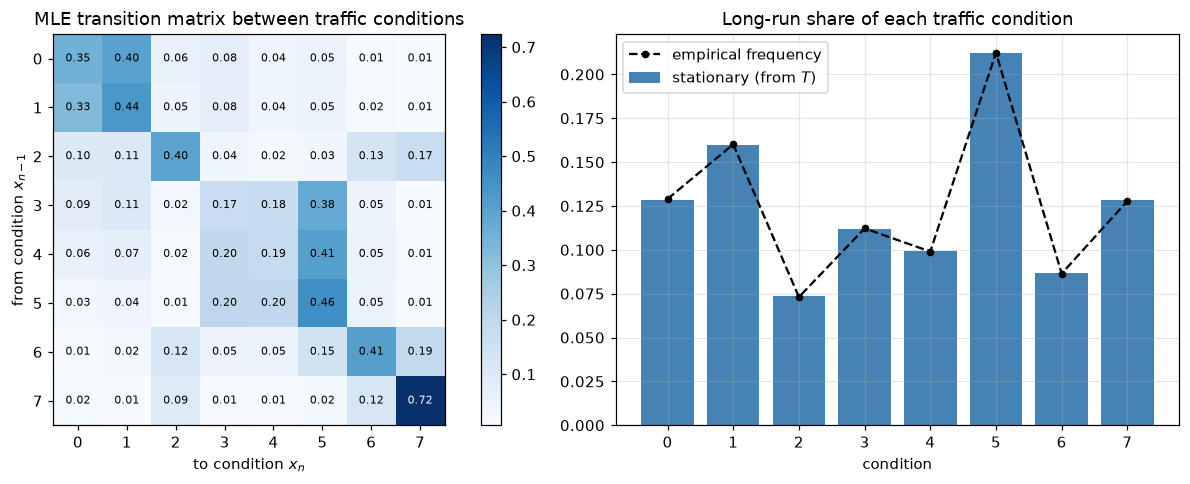

In [5]:
def fit_markov_chain(seqs, M, alpha=1.0):
    init = np.full(M, alpha)
    counts = np.full((M, M), alpha)
    for s in seqs:
        init[s[0]] += 1
        np.add.at(counts, (s[:-1], s[1:]), 1)
    return init / init.sum(), counts / counts.sum(axis=1, keepdims=True)

def markov_loglik(s, p0, T):
    return np.log(p0[s[0]]) + np.log(T[s[:-1], s[1:]]).sum()

p0_mc, T_mc = fit_markov_chain(Xtrain, M)

# stationary distribution: left eigenvector of T with eigenvalue 1
w, v = np.linalg.eig(T_mc.T)
stat = np.real(v[:, np.argmin(np.abs(w - 1))]); stat /= stat.sum()

# Compare with an i.i.d. (zeroth-order) model to show the sequential dependence
unigram = np.bincount(np.concatenate(Xtrain), minlength=M) / sum(map(len, Xtrain))
n_test = sum(map(len, Xtest))
ll_mc  = sum(markov_loglik(s, p0_mc, T_mc) for s in Xtest) / n_test
ll_iid = sum(np.log(unigram[s]).sum() for s in Xtest) / n_test
print(f"Avg test log-likelihood per window: Markov chain = {ll_mc:.4f}, i.i.d. model = {ll_iid:.4f}")
print(f"Perplexity: Markov = {np.exp(-ll_mc):.3f}, i.i.d. = {np.exp(-ll_iid):.3f}  (lower is better)")
print("Stationary distribution of traffic conditions:", stat.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1.3, 1]})
im = ax[0].imshow(T_mc, cmap='Blues')
for i, j in product(range(M), range(M)):
    ax[0].text(j, i, f"{T_mc[i, j]:.2f}", ha='center', va='center', fontsize=7,
               color='white' if T_mc[i, j] > 0.5 else 'black')
ax[0].set(title='MLE transition matrix between traffic conditions', xlabel='to condition $x_n$',
          ylabel='from condition $x_{n-1}$', xticks=range(M), yticks=range(M)); ax[0].grid(False)
plt.colorbar(im, ax=ax[0], fraction=0.046)
ax[1].bar(range(M), stat, color='steelblue', label='stationary (from $T$)')
ax[1].plot(range(M), unigram, 'ko--', ms=4, label='empirical frequency')
ax[1].set(title='Long-run share of each traffic condition', xlabel='condition'); ax[1].legend()
plt.tight_layout(); plt.show()


## 2. Hidden Markov Model with states Normal / Suspicious / Attack



Estimated initial distribution pi: [0.818 0.121 0.061]

Estimated transition matrix A (rows = from, cols = to):


,Normal,Suspicious,Attack
Normal,0.968,0.027,0.005
Suspicious,0.076,0.860,0.063
Attack,0.040,0.055,0.904


True transition matrix used by the simulator (for comparison):


,Normal,Suspicious,Attack
Normal,0.97,0.025,0.005
Suspicious,0.08,0.860,0.060
Attack,0.04,0.060,0.900


Max absolute error |A_hat - A_true| = 0.0047


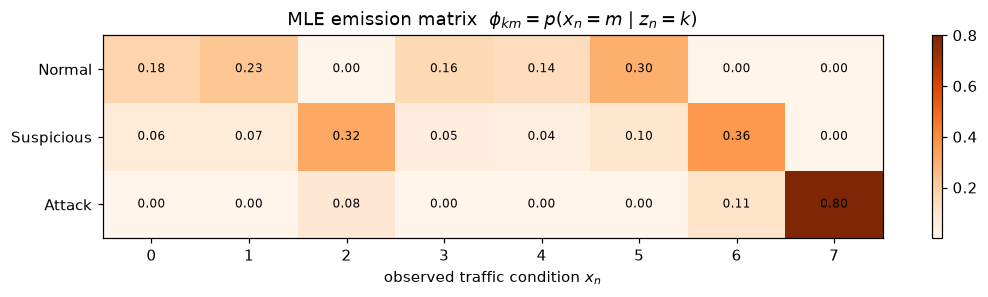

In [6]:
def fit_hmm_mle(obs_seqs, state_seqs, K, M, alpha=1.0):
    pi = np.full(K, alpha); A = np.full((K, K), alpha); B = np.full((K, M), alpha)
    for x, z in zip(obs_seqs, state_seqs):
        pi[z[0]] += 1
        np.add.at(A, (z[:-1], z[1:]), 1)
        np.add.at(B, (z, x), 1)
    return pi / pi.sum(), A / A.sum(1, keepdims=True), B / B.sum(1, keepdims=True)

pi_hat, A_hat, B_hat = fit_hmm_mle(Xtrain, Ztrain, K, M)

print("Estimated initial distribution pi:", pi_hat.round(3))
print("\nEstimated transition matrix A (rows = from, cols = to):")
display(pd.DataFrame(A_hat, index=STATES, columns=STATES))
print("True transition matrix used by the simulator (for comparison):")
display(pd.DataFrame(A_TRUE, index=STATES, columns=STATES))
print(f"Max absolute error |A_hat - A_true| = {np.abs(A_hat - A_TRUE).max():.4f}")

fig, ax = plt.subplots(figsize=(10, 2.8))
im = ax.imshow(B_hat, cmap='Oranges', aspect='auto')
for i, j in product(range(K), range(M)):
    ax.text(j, i, f"{B_hat[i, j]:.2f}", ha='center', va='center', fontsize=8)
ax.set(yticks=range(K), yticklabels=STATES, xticks=range(M), xlabel='observed traffic condition $x_n$',
       title='MLE emission matrix  $\\phi_{km} = p(x_n = m \\mid z_n = k)$'); ax.grid(False)
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()

The estimated transition matrix is very close to the generator's true matrix, and the emission matrix shows that each hidden state emits a characteristic set of traffic conditions with some overlap (because of the stealthy windows). This overlap is exactly why we need inference over the whole sequence rather than per-window rules.

## 3. Forward, Backward and Sum-Product algorithms

**Forward recursion** ($\alpha(z_n) = p(x_1,\dots,x_n, z_n)$):
$$\alpha(z_1) = \pi_{z_1}\,p(x_1\mid z_1),\qquad \alpha(z_n) = p(x_n\mid z_n)\sum_{z_{n-1}}\alpha(z_{n-1})\,A_{z_{n-1}z_n}$$

**Backward recursion** ($\beta(z_n) = p(x_{n+1},\dots,x_N\mid z_n)$):
$$\beta(z_N)=1,\qquad \beta(z_n) = \sum_{z_{n+1}}\beta(z_{n+1})\,p(x_{n+1}\mid z_{n+1})\,A_{z_n z_{n+1}}$$

**Likelihood and posteriors:**
$$p(\mathbf X)=\sum_{z_N}\alpha(z_N),\qquad \gamma(z_n)=\frac{\alpha(z_n)\beta(z_n)}{p(\mathbf X)},\qquad \xi(z_{n-1},z_n)=\frac{\alpha(z_{n-1})\,p(x_n\mid z_n)\,A_{z_{n-1}z_n}\,\beta(z_n)}{p(\mathbf X)}$$

In [7]:
def forward(x, pi, A, B):
    T = len(x); alpha = np.zeros((T, len(pi)))
    alpha[0] = pi * B[:, x[0]]
    for n in range(1, T):
        alpha[n] = B[:, x[n]] * (alpha[n - 1] @ A)
    return alpha

def backward(x, A, B):
    T = len(x); beta = np.ones((T, A.shape[0]))
    for n in range(T - 2, -1, -1):
        beta[n] = A @ (B[:, x[n + 1]] * beta[n + 1])
    return beta

def forward_backward(x, pi, A, B):
    alpha, beta = forward(x, pi, A, B), backward(x, A, B)
    px = alpha[-1].sum()
    gamma = alpha * beta / px
    xi = np.array([alpha[n - 1][:, None] * A * (B[:, x[n]] * beta[n])[None, :]
                   for n in range(1, len(x))]) / px
    return px, gamma, xi, alpha, beta

# demonstrate on a short 60-window segment that contains an incident
seg_start = int(np.argmax(Ztest[0] == 2)) - 25
seg_start = max(seg_start, 0)
xs, zs = Xtest[0][seg_start:seg_start + 60], Ztest[0][seg_start:seg_start + 60]
px, gamma, xi, alpha, beta = forward_backward(xs, pi_hat, A_hat, B_hat)

print(f"Segment length N = {len(xs)}")
print(f"p(X) from forward  = sum_z alpha(z_N)          = {px:.6e}")
print(f"p(X) from backward = sum_z pi p(x1|z) beta(z1) = {(pi_hat * B_hat[:, xs[0]] * beta[0]).sum():.6e}")
print(f"p(X) at every n    = sum_z alpha(z_n) beta(z_n): min {np.min((alpha * beta).sum(1)):.6e}, "
      f"max {np.max((alpha * beta).sum(1)):.6e}")
print(f"log p(X) = {np.log(px):.4f}")
print("gamma rows sum to 1:", np.allclose(gamma.sum(1), 1), "| xi sums to 1 per step:", np.allclose(xi.sum((1, 2)), 1))

Segment length N = 60
p(X) from forward  = sum_z alpha(z_N)          = 3.937931e-49
p(X) from backward = sum_z pi p(x1|z) beta(z1) = 3.937931e-49
p(X) at every n    = sum_z alpha(z_n) beta(z_n): min 3.937931e-49, max 3.937931e-49
log p(X) = -111.4560
gamma rows sum to 1: True | xi sums to 1 per step: True


**Brute-force verification.** For a tiny sequence we can enumerate all $K^N$ hidden paths and sum $p(\mathbf X,\mathbf Z)$ directly. The forward algorithm must give the same value but in $O(NK^2)$ instead of $O(K^N)$.

In [8]:
def brute_force_likelihood(x, pi, A, B):
    total = 0.0
    for path in product(range(len(pi)), repeat=len(x)):
        p = pi[path[0]] * B[path[0], x[0]]
        for n in range(1, len(x)):
            p *= A[path[n - 1], path[n]] * B[path[n], x[n]]
        total += p
    return total

x_tiny = xs[20:28]
bf = brute_force_likelihood(x_tiny, pi_hat, A_hat, B_hat)
fw = forward(x_tiny, pi_hat, A_hat, B_hat)[-1].sum()
print(f"N = {len(x_tiny)}, paths enumerated = {K ** len(x_tiny)}")
print(f"Brute force p(X) = {bf:.10e}\nForward     p(X) = {fw:.10e}\nMatch: {np.isclose(bf, fw)}")

N = 8, paths enumerated = 6561
Brute force p(X) = 2.4145503014e-07
Forward     p(X) = 2.4145503014e-07
Match: True


### 3.1 Sum-Product algorithm on the HMM factor graph

The HMM is a chain-structured factor graph with factors
$$h(z_1) = \pi_{z_1}\,p(x_1\mid z_1),\qquad f_n(z_{n-1},z_n) = A_{z_{n-1}z_n}\,p(x_n\mid z_n).$$
Because every variable node has exactly two neighbouring factors, a variable simply forwards the message it receives. The sum-product messages are
$$\mu_{f_n\to z_n}(z_n)=\sum_{z_{n-1}} f_n(z_{n-1},z_n)\,\mu_{f_{n-1}\to z_{n-1}}(z_{n-1}),\qquad
\mu_{f_{n+1}\to z_n}(z_n)=\sum_{z_{n+1}} f_{n+1}(z_n,z_{n+1})\,\mu_{f_{n+2}\to z_{n+1}}(z_{n+1}),$$
and the marginal at each variable is the product of its incoming messages, $p(z_n,\mathbf X)=\mu_{f_n\to z_n}(z_n)\,\mu_{f_{n+1}\to z_n}(z_n)$. Below, the algorithm is written in this generic message-passing form, with each factor built as an explicit table; the result is checked against the forward-backward posteriors, showing that $\alpha$ and $\beta$ *are* the sum-product messages (Bishop §13.2.3).

Sum-product p(X)      = 3.937931e-49  (forward-backward: 3.937931e-49)
Single-node marginals equal gamma : True
Pairwise marginals equal xi       : True


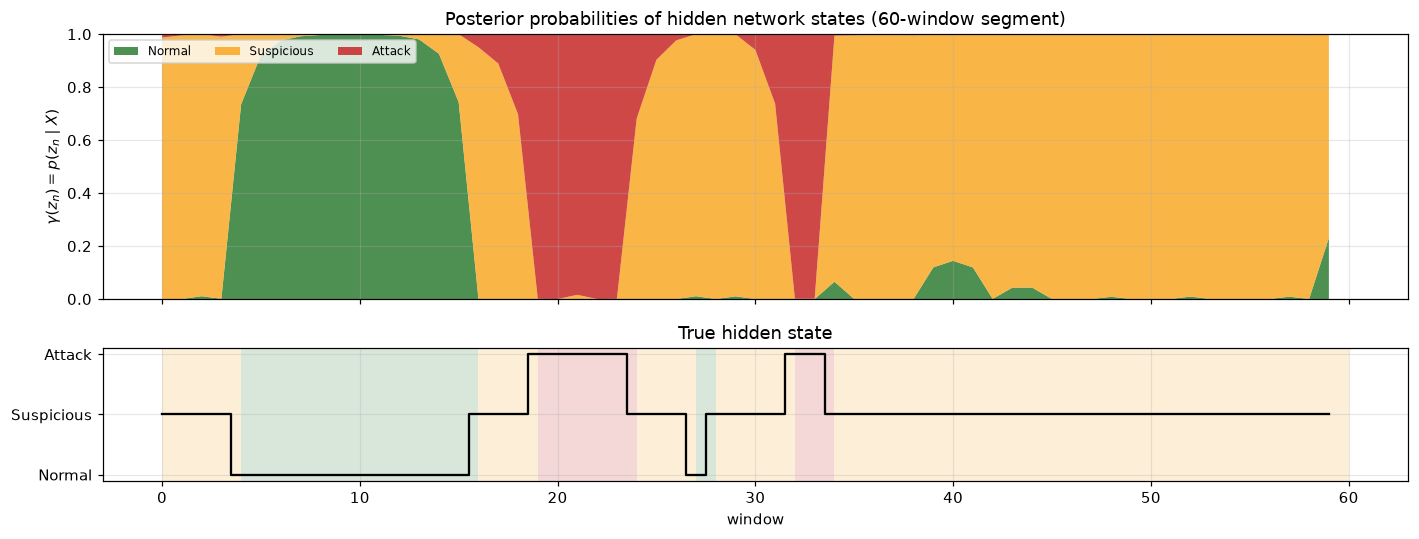

In [9]:
def sum_product_hmm(x, pi, A, B):
    N, Kz = len(x), len(pi)
    # factor tables
    h = pi * B[:, x[0]]                                           # h(z1)
    f = [None] + [A * B[:, x[n]][None, :] for n in range(1, N)]   # f_n(z_{n-1}, z_n)

    # messages from leaf h towards the root (left -> right)
    msg_right = np.zeros((N, Kz)); msg_right[0] = h
    for n in range(1, N):
        msg_var_to_factor = msg_right[n - 1]                      # z_{n-1} -> f_n
        msg_right[n] = (f[n] * msg_var_to_factor[:, None]).sum(axis=0)   # sum over z_{n-1}

    # messages from the right end towards the left (right -> left)
    msg_left = np.ones((N, Kz))                                   # z_N is a leaf: message = 1
    for n in range(N - 2, -1, -1):
        msg_var_to_factor = msg_left[n + 1]                       # z_{n+1} -> f_{n+1}
        msg_left[n] = (f[n + 1] * msg_var_to_factor[None, :]).sum(axis=1)  # sum over z_{n+1}

    joint = msg_right * msg_left                                  # p(z_n, X)
    pX = joint[0].sum()
    marginals = joint / pX
    pairwise = np.array([msg_right[n - 1][:, None] * f[n] * msg_left[n][None, :]
                         for n in range(1, N)]) / pX              # p(z_{n-1}, z_n | X)
    return pX, marginals, pairwise

px_sp, gamma_sp, xi_sp = sum_product_hmm(xs, pi_hat, A_hat, B_hat)
print(f"Sum-product p(X)      = {px_sp:.6e}  (forward-backward: {px:.6e})")
print("Single-node marginals equal gamma :", np.allclose(gamma_sp, gamma))
print("Pairwise marginals equal xi       :", np.allclose(xi_sp, xi))

fig, ax = plt.subplots(2, 1, figsize=(13, 5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
ax[0].stackplot(np.arange(len(xs)), gamma.T, colors=STATE_COLORS, labels=STATES, alpha=0.85)
ax[0].set(ylabel='$\\gamma(z_n)=p(z_n\\mid X)$', title='Posterior probabilities of hidden network states (60-window segment)')
ax[0].legend(loc='upper left', fontsize=8, ncol=3); ax[0].set_ylim(0, 1)
ax[1].step(np.arange(len(zs)), zs, where='mid', color='k')
shade_states(ax[1], zs)
ax[1].set(yticks=range(K), yticklabels=STATES, xlabel='window', title='True hidden state')
plt.tight_layout(); plt.show()

## 4. Scaling factors and Viterbi decoding

### 4.1 Why scaling is needed
Each $\alpha(z_n)$ is a joint probability of $n$ observations, so it shrinks geometrically. For a full session of 576 windows the raw forward variables underflow to exactly zero in double precision, and $\ln p(\mathbf X)$ becomes $-\infty$.

In [10]:
x_full = Xtest[0]
alpha_raw = forward(x_full, pi_hat, A_hat, B_hat)
first_zero = int(np.argmax(alpha_raw.sum(1) == 0)) if np.any(alpha_raw.sum(1) == 0) else None
with np.errstate(divide='ignore'):
    print(f"Sequence length N = {len(x_full)}")
    print(f"Unscaled sum_z alpha(z_N) = {alpha_raw[-1].sum()}  ->  log p(X) = {np.log(alpha_raw[-1].sum())}")
print(f"Underflow to 0.0 first occurs at window n = {first_zero}")

Sequence length N = 576
Unscaled sum_z alpha(z_N) = 0.0  ->  log p(X) = -inf
Underflow to 0.0 first occurs at window n = 478


### 4.2 Scaled Forward-Backward
Define normalised variables and scaling factors (Bishop §13.2.4):
$$\hat\alpha(z_n) = p(z_n\mid x_1,\dots,x_n) = \frac{\alpha(z_n)}{p(x_1,\dots,x_n)},\qquad c_n = p(x_n\mid x_1,\dots,x_{n-1}).$$
$$c_n\,\hat\alpha(z_n) = p(x_n\mid z_n)\sum_{z_{n-1}}\hat\alpha(z_{n-1})A_{z_{n-1}z_n},\qquad c_{n+1}\hat\beta(z_n)=\sum_{z_{n+1}}\hat\beta(z_{n+1})\,p(x_{n+1}\mid z_{n+1})A_{z_nz_{n+1}}$$
$$\ln p(\mathbf X)=\sum_{n=1}^{N}\ln c_n,\qquad \gamma(z_n)=\hat\alpha(z_n)\hat\beta(z_n),\qquad \xi(z_{n-1},z_n)=c_n^{-1}\,\hat\alpha(z_{n-1})\,p(x_n\mid z_n)\,A_{z_{n-1}z_n}\,\hat\beta(z_n).$$
All quantities stay in a numerically safe range. As a third independent check, a log-space forward pass using log-sum-exp is also implemented.

In [11]:
def forward_scaled(x, pi, A, B):
    N = len(x); a_hat = np.zeros((N, len(pi))); c = np.zeros(N)
    a = pi * B[:, x[0]]; c[0] = a.sum(); a_hat[0] = a / c[0]
    for n in range(1, N):
        a = B[:, x[n]] * (a_hat[n - 1] @ A)
        c[n] = a.sum(); a_hat[n] = a / c[n]
    return a_hat, c

def backward_scaled(x, A, B, c):
    N = len(x); b_hat = np.ones((N, A.shape[0]))
    for n in range(N - 2, -1, -1):
        b_hat[n] = (A @ (B[:, x[n + 1]] * b_hat[n + 1])) / c[n + 1]
    return b_hat

def posteriors_scaled(x, pi, A, B):
    a_hat, c = forward_scaled(x, pi, A, B)
    b_hat = backward_scaled(x, A, B, c)
    gamma = a_hat * b_hat
    xi = (a_hat[:-1, :, None] * A[None] * (B[:, x[1:]].T * b_hat[1:])[:, None, :]) / c[1:, None, None]
    return np.log(c).sum(), gamma, xi, a_hat, c

def forward_log(x, pi, A, B):
    la = np.log(pi) + np.log(B[:, x[0]]); lA = np.log(A)
    for n in range(1, len(x)):
        la = np.log(B[:, x[n]]) + logsumexp(la[:, None] + lA, axis=0)
    return logsumexp(la)

logpx, gamma_full, xi_full, a_hat_full, c_full = posteriors_scaled(x_full, pi_hat, A_hat, B_hat)
print(f"Scaled forward:     log p(X) = sum ln c_n = {logpx:.6f}")
print(f"Log-space forward:  log p(X)              = {forward_log(x_full, pi_hat, A_hat, B_hat):.6f}")
print(f"Range of c_n: [{c_full.min():.4f}, {c_full.max():.4f}]   (no underflow)")
print("gamma rows sum to 1:", np.allclose(gamma_full.sum(1), 1))

# check against the unscaled implementation on the short segment
lp_s, g_s, xi_s, _, _ = posteriors_scaled(xs, pi_hat, A_hat, B_hat)
print("Scaled == unscaled on short segment (log p, gamma, xi):",
      np.isclose(lp_s, np.log(px)), np.allclose(g_s, gamma), np.allclose(xi_s, xi))

Scaled forward:     log p(X) = sum ln c_n = -915.916604
Log-space forward:  log p(X)              = -915.916604
Range of c_n: [0.0048, 0.7237]   (no underflow)
gamma rows sum to 1: True
Scaled == unscaled on short segment (log p, gamma, xi): True True True


### 4.3 Viterbi decoding (max-sum algorithm)
The posterior $\gamma$ gives the most probable state *at each window individually*, but the most probable *sequence* of network activities is
$$\mathbf Z^\star=\arg\max_{\mathbf Z}\ln p(\mathbf X,\mathbf Z).$$
Viterbi computes it with the max-sum recursion in log-space (which needs no scaling, because sums of logs do not underflow):
$$\omega(z_1)=\ln\pi_{z_1}+\ln p(x_1\mid z_1),\qquad \omega(z_n)=\ln p(x_n\mid z_n)+\max_{z_{n-1}}\{\ln A_{z_{n-1}z_n}+\omega(z_{n-1})\}$$
with back-pointers $\psi(z_n)=\arg\max_{z_{n-1}}\{\cdot\}$, followed by back-tracking from $z_N^\star=\arg\max\omega(z_N)$.

In [12]:
def viterbi(x, pi, A, B):
    N, Kz = len(x), len(pi)
    lA, lB = np.log(A), np.log(B)
    omega = np.zeros((N, Kz)); psi = np.zeros((N, Kz), dtype=int)
    omega[0] = np.log(pi) + lB[:, x[0]]
    for n in range(1, N):
        scores = omega[n - 1][:, None] + lA          # [from, to]
        psi[n] = scores.argmax(axis=0)
        omega[n] = scores.max(axis=0) + lB[:, x[n]]
    path = np.zeros(N, dtype=int); path[-1] = omega[-1].argmax()
    for n in range(N - 1, 0, -1):
        path[n - 1] = psi[n, path[n]]
    return path, omega[-1].max()

def joint_logprob(x, z, pi, A, B):
    return np.log(pi[z[0]]) + np.log(A[z[:-1], z[1:]]).sum() + np.log(B[z, x]).sum()

# brute-force check of Viterbi on the tiny sequence
best = max(product(range(K), repeat=len(x_tiny)), key=lambda p: joint_logprob(x_tiny, np.array(p), pi_hat, A_hat, B_hat))
vpath, vscore = viterbi(x_tiny, pi_hat, A_hat, B_hat)
print("Viterbi path    :", vpath, f"log p = {vscore:.4f}")
print("Brute-force best:", np.array(best), f"log p = {joint_logprob(x_tiny, np.array(best), pi_hat, A_hat, B_hat):.4f}")

vit_full, _ = viterbi(x_full, pi_hat, A_hat, B_hat)
print(f"\nFull test session 0: log p(X, Z*) = {joint_logprob(x_full, vit_full, pi_hat, A_hat, B_hat):.2f}"
      f"  <=  log p(X) = {logpx:.2f}")

Viterbi path    : [2 2 2 2 1 1 1 1] log p = -15.9376
Brute-force best: [2 2 2 2 1 1 1 1] log p = -15.9376

Full test session 0: log p(X, Z*) = -931.70  <=  log p(X) = -915.92


### 4.4 Evaluation on all test sessions

Three decoders are compared on 10 unseen test sessions (5,760 windows):

1. **Per-window baseline** - classifies each window independently, $\arg\max_k \pi^{\text{stat}}_k\,p(x_n\mid z_n=k)$, ignoring temporal context.
2. **Posterior decoding** - $\arg\max_k \gamma(z_n=k)$ from scaled forward-backward.
3. **Viterbi** - the single most probable state sequence.

Also reported: an **online** detector that uses only past data, the filtered posterior $\hat\alpha(z_n)=p(z_n\mid x_{1:n})$, raising an alarm when $p(\text{Attack}\mid x_{1:n})>0.5$. This is what a deployed IDS would run in real time.

In [13]:
w_, v_ = np.linalg.eig(A_hat.T)
pi_stat = np.real(v_[:, np.argmin(np.abs(w_ - 1))]); pi_stat /= pi_stat.sum()

y_true, y_base, y_post, y_vit, y_filt = [], [], [], [], []
test_loglik = []
for x, z in zip(Xtest, Ztest):
    lp, g, _, a_hat, _ = posteriors_scaled(x, pi_hat, A_hat, B_hat)
    test_loglik.append(lp)
    y_true.append(z)
    y_base.append(np.argmax(pi_stat[:, None] * B_hat[:, x], axis=0))
    y_post.append(g.argmax(1))
    y_vit.append(viterbi(x, pi_hat, A_hat, B_hat)[0])
    y_filt.append(a_hat.argmax(1))
y_true, y_base, y_post, y_vit, y_filt = map(np.concatenate, (y_true, y_base, y_post, y_vit, y_filt))

results = pd.DataFrame({
    'Decoder': ['Per-window baseline (no temporal model)', 'HMM filtering (online, causal)',
                'HMM posterior decoding (gamma)', 'HMM Viterbi (most likely sequence)'],
    'Accuracy': [accuracy_score(y_true, y) for y in (y_base, y_filt, y_post, y_vit)],
})
for name, y in zip(results['Decoder'], (y_base, y_filt, y_post, y_vit)):
    cm = confusion_matrix(y_true, y, labels=range(K))
    results.loc[results['Decoder'] == name, 'Attack recall'] = cm[2, 2] / cm[2].sum()
    results.loc[results['Decoder'] == name, 'Attack precision'] = cm[2, 2] / cm[:, 2].sum()
    results.loc[results['Decoder'] == name, 'Suspicious recall'] = cm[1, 1] / cm[1].sum()
print(f"Mean test log-likelihood per session: {np.mean(test_loglik):.2f}")
results

Mean test log-likelihood per session: -954.62


,Decoder,Accuracy,Attack recall,Attack precision,Suspicious recall
0,Per-window baseline (no temporal model),0.927,0.806,0.998,0.709
1,"HMM filtering (online, causal)",0.958,0.963,0.933,0.849
2,HMM posterior decoding (gamma),0.981,0.959,0.975,0.929
3,HMM Viterbi (most likely sequence),0.981,0.959,0.975,0.932


Viterbi decoding - classification report (test set):

              precision    recall  f1-score   support

      Normal      0.988     0.997     0.992      4097
  Suspicious      0.956     0.932     0.944       984
      Attack      0.975     0.959     0.967       679

    accuracy                          0.981      5760
   macro avg      0.973     0.962     0.968      5760
weighted avg      0.981     0.981     0.981      5760



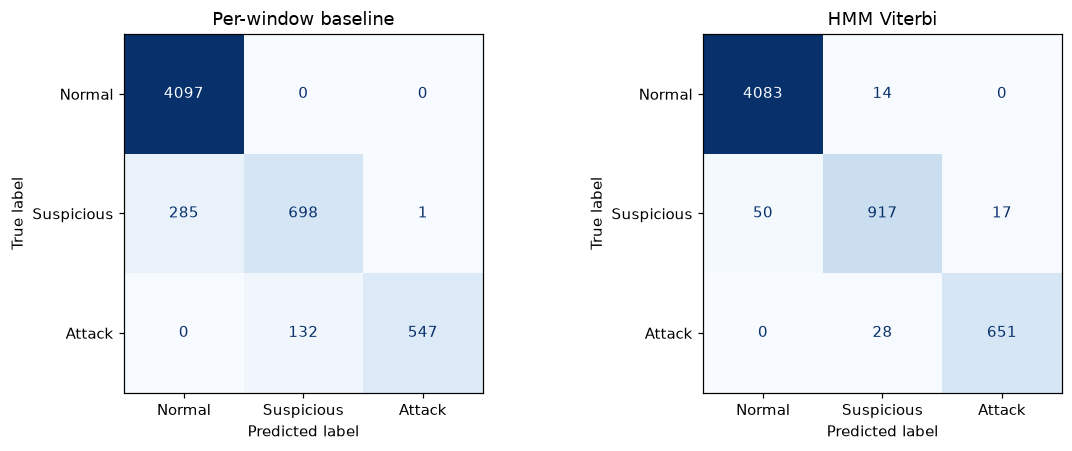

In [14]:
print("Viterbi decoding - classification report (test set):\n")
print(classification_report(y_true, y_vit, target_names=STATES, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, y, t in zip(ax, (y_base, y_vit), ('Per-window baseline', 'HMM Viterbi')):
    ConfusionMatrixDisplay(confusion_matrix(y_true, y, labels=range(K)), display_labels=STATES).plot(
        ax=a, cmap='Blues', colorbar=False, values_format='d')
    a.set_title(t); a.grid(False)
plt.tight_layout(); plt.show()

In [15]:
def episodes(z, k):
    # start/end indices of contiguous runs of state k
    runs, n = [], 0
    while n < len(z):
        if z[n] == k:
            m = n
            while m + 1 < len(z) and z[m + 1] == k: m += 1
            runs.append((n, m)); n = m + 1
        else:
            n += 1
    return runs

detected, delays, false_alarm_windows, normal_windows = 0, [], 0, 0
for x, z in zip(Xtest, Ztest):
    a_hat, _ = forward_scaled(x, pi_hat, A_hat, B_hat)
    alarm = a_hat[:, 2] > 0.5
    for s, e in episodes(z, 2):
        hits = np.where(alarm[s:e + 1])[0]
        if len(hits): detected += 1; delays.append(hits[0])
    false_alarm_windows += np.sum(alarm & (z == 0)); normal_windows += np.sum(z == 0)

n_eps = sum(len(episodes(z, 2)) for z in Ztest)
print("Online attack detector (filtered posterior P(Attack | x_1:n) > 0.5)")
print(f"  Attack episodes detected : {detected}/{n_eps} ({100 * detected / n_eps:.1f}%)")
print(f"  Mean detection delay     : {np.mean(delays):.2f} windows ({5 * np.mean(delays):.1f} minutes)")
print(f"  False-alarm rate         : {100 * false_alarm_windows / normal_windows:.2f}% of Normal windows")

Online attack detector (filtered posterior P(Attack | x_1:n) > 0.5)
  Attack episodes detected : 83/84 (98.8%)
  Mean detection delay     : 0.17 windows (0.8 minutes)
  False-alarm rate         : 0.00% of Normal windows


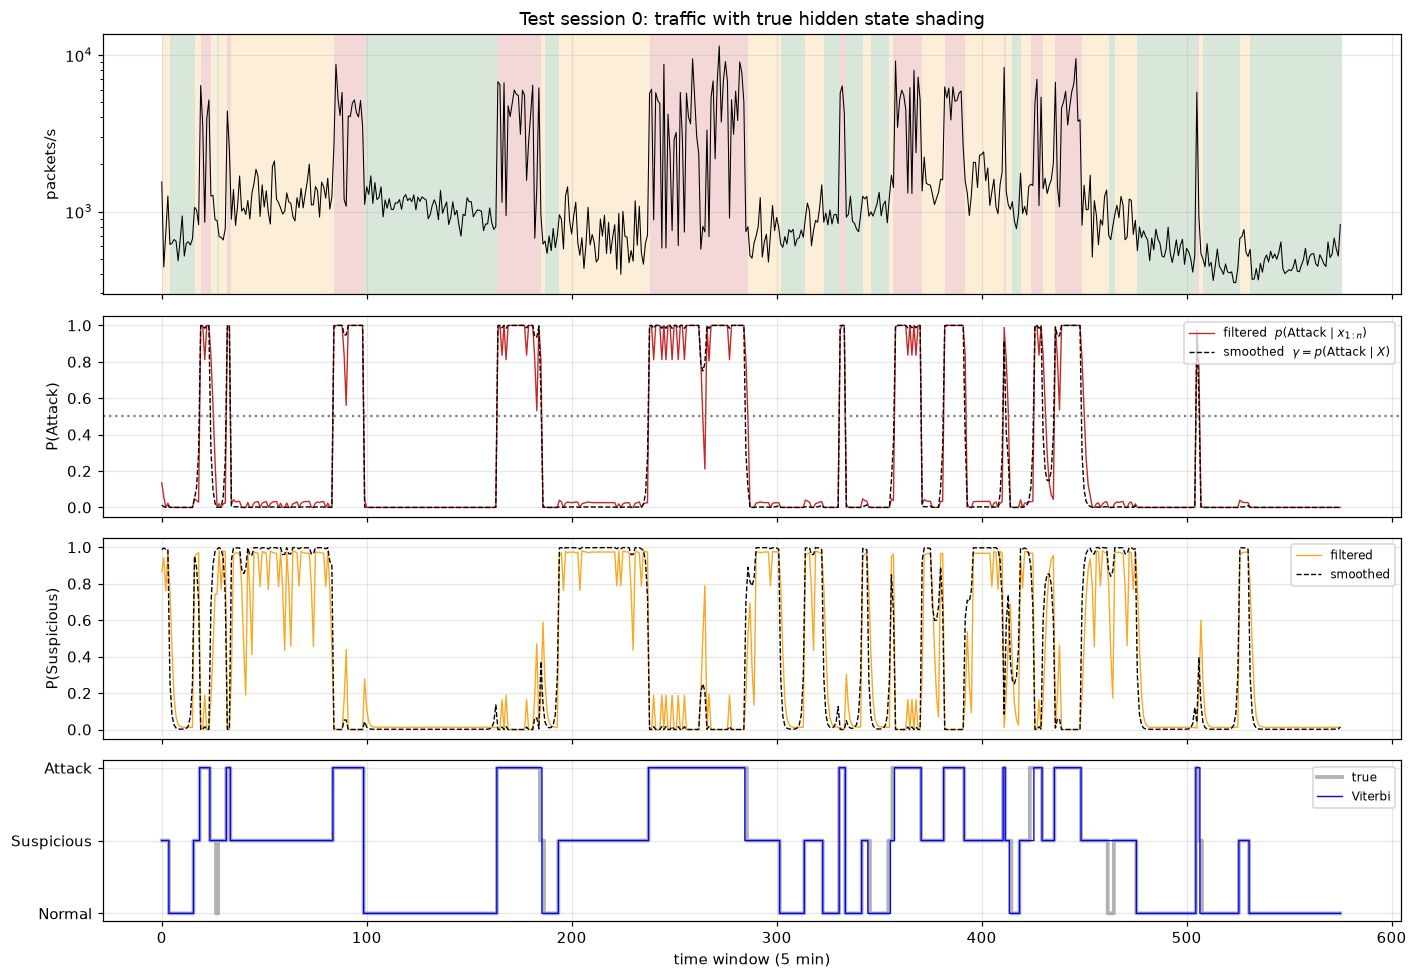

In [16]:
s_idx = 0
x, z, df = Xtest[s_idx], Ztest[s_idx], test_sessions[s_idx]
_, g, _, a_hat, _ = posteriors_scaled(x, pi_hat, A_hat, B_hat)
vp = viterbi(x, pi_hat, A_hat, B_hat)[0]

fig, ax = plt.subplots(4, 1, figsize=(13, 9), sharex=True, gridspec_kw={'height_ratios': [1.3, 1, 1, 0.8]})
ax[0].semilogy(df['pkt_rate'].values, 'k', lw=0.7); shade_states(ax[0], z)
ax[0].set(ylabel='packets/s', title=f'Test session {s_idx}: traffic with true hidden state shading')
ax[1].plot(a_hat[:, 2], color=STATE_COLORS[2], lw=0.9, label='filtered  $p(\\mathrm{Attack}\\mid x_{1:n})$')
ax[1].plot(g[:, 2], color='k', lw=0.9, ls='--', label='smoothed  $\\gamma = p(\\mathrm{Attack}\\mid X)$')
ax[1].axhline(0.5, color='grey', ls=':'); ax[1].legend(loc='upper right', fontsize=8); ax[1].set_ylabel('P(Attack)')
ax[2].plot(a_hat[:, 1], color=STATE_COLORS[1], lw=0.9, label='filtered')
ax[2].plot(g[:, 1], color='k', lw=0.9, ls='--', label='smoothed'); ax[2].legend(loc='upper right', fontsize=8)
ax[2].set_ylabel('P(Suspicious)')
ax[3].step(range(len(z)), z, where='mid', color='grey', lw=2.5, alpha=0.6, label='true')
ax[3].step(range(len(vp)), vp, where='mid', color='b', lw=0.9, label='Viterbi')
ax[3].set(yticks=range(K), yticklabels=STATES, xlabel='time window (5 min)'); ax[3].legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.** The per-window baseline confuses stealthy Suspicious windows with Normal ones and pulsing Attack windows with Suspicious ones. The HMM uses the transition structure (attacks and scans persist over many windows) to "fill in" those ambiguous windows, so posterior and Viterbi decoding are clearly more accurate. The online filtered detector raises alarms within a few minutes of an attack starting, with a low false-alarm rate.

### 4.5 Extension: MLE without labels - Baum-Welch (EM)
In practice labelled traffic is scarce. EM maximises the *incomplete-data* likelihood $p(\mathbf X\mid\theta)$ using the scaled $\gamma$ and $\xi$ from §4.2:
$$\pi_k=\frac{\sum_s\gamma_s(z_{1k})}{S},\quad A_{jk}=\frac{\sum_s\sum_{n=2}^{N}\xi_s(z_{n-1,j},z_{nk})}{\sum_s\sum_{n=2}^{N}\sum_l\xi_s(z_{n-1,j},z_{nl})},\quad \phi_{km}=\frac{\sum_s\sum_n\gamma_s(z_{nk})\,[x_n=m]}{\sum_s\sum_n\gamma_s(z_{nk})}.$$
EM is run from several random initialisations and the solution with the highest likelihood is kept. Learned states carry no names, so each is mapped to the security label it most often coincides with on the training data (labels are used *only* for naming, never for fitting).

K = 3 hidden states: EM log-likelihood -25304.1 after 44 iterations, monotone: True, test accuracy 0.8276
K = 4 hidden states: EM log-likelihood -23964.1 after 32 iterations, monotone: True, test accuracy 0.9731

For reference, the supervised (label-based) MLE parameters give train log-likelihood -28133.3

K = 3: how the learned states line up with the true labels (training windows)


,Normal,Suspicious,Attack
EM state 0 (~973 pkt/s) -> Normal,6475,443,0
EM state 1 (~2793 pkt/s) -> Attack,19,2281,2750
EM state 2 (~574 pkt/s) -> Normal,4801,511,0



K = 4: how the learned states line up with the true labels (training windows)


,Normal,Suspicious,Attack
EM state 0 (~4223 pkt/s) -> Attack,0,49,2637
EM state 1 (~566 pkt/s) -> Normal,4798,127,1
EM state 2 (~1030 pkt/s) -> Suspicious,67,2840,112
EM state 3 (~969 pkt/s) -> Normal,6430,219,0


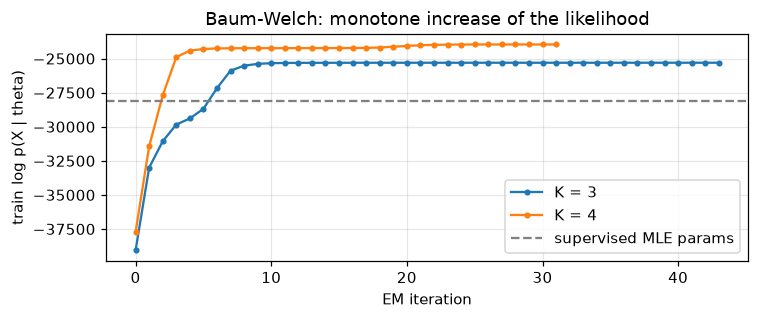

In [17]:
def baum_welch(obs_seqs, K, M, n_iter=300, tol=1e-6, rng=None):
    rng = rng or np.random.default_rng(0)
    pi = rng.dirichlet(np.ones(K))
    A = rng.dirichlet(np.ones(K), size=K) + np.eye(K) * 2; A /= A.sum(1, keepdims=True)
    B = rng.dirichlet(np.ones(M), size=K)
    history = []
    for it in range(n_iter):
        pi_num = np.zeros(K); A_num = np.zeros((K, K)); B_num = np.zeros((K, M)); ll = 0.0
        for x in obs_seqs:                                    # E-step
            lp, g, xi, _, _ = posteriors_scaled(x, pi, A, B)
            ll += lp; pi_num += g[0]; A_num += xi.sum(0)
            for m in range(M): B_num[:, m] += g[x == m].sum(0)
        pi = pi_num / pi_num.sum()                            # M-step
        A = A_num / A_num.sum(1, keepdims=True)
        B = (B_num + 1e-6) / (B_num + 1e-6).sum(1, keepdims=True)
        history.append(ll)
        if it > 0 and abs(history[-1] - history[-2]) < tol * abs(history[-2]): break
    return pi, A, B, history

def best_of_restarts(obs_seqs, K, M, n_restarts=3):
    runs = [baum_welch(obs_seqs, K, M, rng=np.random.default_rng(r)) for r in range(n_restarts)]
    return max(runs, key=lambda r: r[3][-1])

def name_states(params, obs_seqs, state_seqs):
    # map each learned state to the security label it most often coincides with (naming only)
    pi, A, B, _ = params
    z_em = np.concatenate([viterbi(x, pi, A, B)[0] for x in obs_seqs])
    cm = confusion_matrix(z_em, np.concatenate(state_seqs), labels=range(len(pi)))[:, :K]
    return cm.argmax(1), cm

ll_sup = sum(posteriors_scaled(x, pi_hat, A_hat, B_hat)[0] for x in Xtrain)
em_results = {}
for K_em in (3, 4):
    params = best_of_restarts(Xtrain, K_em, M)
    mapping, cm = name_states(params, Xtrain, Ztrain)
    y_em_k = np.concatenate([mapping[viterbi(x, *params[:3])[0]] for x in Xtest])
    em_results[K_em] = dict(params=params, mapping=mapping, cm=cm, acc=accuracy_score(y_true, y_em_k))
    print(f"K = {K_em} hidden states: EM log-likelihood {params[3][-1]:.1f} after {len(params[3])} iterations, "
          f"monotone: {np.all(np.diff(params[3]) > -1e-6)}, test accuracy {em_results[K_em]['acc']:.4f}")
print(f"\nFor reference, the supervised (label-based) MLE parameters give train log-likelihood {ll_sup:.1f}")

for K_em in (3, 4):
    r = em_results[K_em]
    load = (cond_table['pkt_rate'].values[None, :] * r['params'][2]).sum(1)   # expected pkt rate per EM state
    print(f"\nK = {K_em}: how the learned states line up with the true labels (training windows)")
    display(pd.DataFrame(r['cm'], index=[f"EM state {i} (~{load[i]:.0f} pkt/s) -> {STATES[r['mapping'][i]]}"
                                         for i in range(K_em)], columns=STATES))

fig, ax = plt.subplots(figsize=(7, 3))
for K_em in (3, 4):
    ax.plot(em_results[K_em]['params'][3], 'o-', ms=3, label=f'K = {K_em}')
ax.axhline(ll_sup, color='grey', ls='--', label='supervised MLE params')
ax.set(xlabel='EM iteration', ylabel='train log p(X | theta)', title='Baum-Welch: monotone increase of the likelihood')
ax.legend(); plt.tight_layout(); plt.show()
y_em = np.concatenate([em_results[4]['mapping'][viterbi(x, *em_results[4]['params'][:3])[0]] for x in Xtest])

**Interpretation.** With exactly three states, EM converges to a solution whose likelihood is *higher* than that of the true-label model, but it spends its states on the biggest source of variation in the data: the daily load cycle. Normal traffic is split into low-load and high-load states, while Suspicious and Attack are merged. Maximum likelihood fits the data; it does not know which distinctions matter for security. Allowing one extra hidden state ($K=4$) gives EM room to model the load cycle *and* separate Suspicious from Attack, and the unsupervised model then approaches the accuracy of the supervised one. This is why the supervised MLE of §2 is used as the main detector, and why choosing the number of hidden states is an important design decision in practice.

## 5. Linear Dynamical System for continuous traffic characteristics

The HMM handles *discrete* conditions. To track and forecast the *continuous* traffic level, a Linear-Gaussian State Space Model (Kalman model) is used:
$$\mathbf z_n=\mathbf A\mathbf z_{n-1}+\mathbf w_n,\quad \mathbf w_n\sim\mathcal N(\mathbf 0,\boldsymbol\Gamma);\qquad \mathbf x_n=\mathbf C\mathbf z_n+\mathbf v_n,\quad \mathbf v_n\sim\mathcal N(\mathbf 0,\boldsymbol\Sigma);\qquad \mathbf z_1\sim\mathcal N(\boldsymbol\mu_0,\mathbf V_0).$$

* **Observations** $\mathbf x_n\in\mathbb R^2$: log packet rate and log average packet size of each window.
* **Latent state** $\mathbf z_n\in\mathbb R^4$: a *level* and a *trend* for each observed characteristic (local linear trend model), initialised with $\mathbf A=\mathrm{blockdiag}\left(\begin{smallmatrix}1&1\\0&1\end{smallmatrix},\begin{smallmatrix}1&1\\0&1\end{smallmatrix}\right)$ and $\mathbf C$ selecting the two levels.

**Inference.**
* *Kalman filter* (forward pass): $\mathbf P_{n-1}=\mathbf A\mathbf V_{n-1}\mathbf A^\top+\boldsymbol\Gamma,\ \mathbf K_n=\mathbf P_{n-1}\mathbf C^\top(\mathbf C\mathbf P_{n-1}\mathbf C^\top+\boldsymbol\Sigma)^{-1},\ \boldsymbol\mu_n=\mathbf A\boldsymbol\mu_{n-1}+\mathbf K_n(\mathbf x_n-\mathbf C\mathbf A\boldsymbol\mu_{n-1}),\ \mathbf V_n=(\mathbf I-\mathbf K_n\mathbf C)\mathbf P_{n-1}$
* *RTS smoother* (backward pass): $\mathbf J_n=\mathbf V_n\mathbf A^\top\mathbf P_n^{-1},\ \hat{\boldsymbol\mu}_n=\boldsymbol\mu_n+\mathbf J_n(\hat{\boldsymbol\mu}_{n+1}-\mathbf A\boldsymbol\mu_n),\ \hat{\mathbf V}_n=\mathbf V_n+\mathbf J_n(\hat{\mathbf V}_{n+1}-\mathbf P_n)\mathbf J_n^\top$

**Learning.** $\mathbf A,\boldsymbol\Gamma,\boldsymbol\Sigma,\boldsymbol\mu_0,\mathbf V_0$ are estimated by **EM** (Bishop §13.3.2), using the smoothed moments $\mathbb E[\mathbf z_n]$, $\mathbb E[\mathbf z_n\mathbf z_n^\top]$ and $\mathbb E[\mathbf z_n\mathbf z_{n-1}^\top]=\hat{\mathbf V}_n\mathbf J_{n-1}^\top+\hat{\boldsymbol\mu}_n\hat{\boldsymbol\mu}_{n-1}^\top$. $\mathbf C$ is kept fixed for identifiability.

LDS EM: log-likelihood -9015.4 -> -3956.7 over 40 iterations
Monotone increase: True

Learned transition matrix A:
 [[ 0.9942  0.8368  0.0063 -0.4903]
 [-0.0115  0.4185  0.0128  0.0274]
 [ 0.0053 -0.4737  0.9942  0.8198]
 [ 0.0147 -0.2388 -0.0162  0.2933]]

Learned process noise Gamma (diag): [0.0087 0.0098 0.0083 0.0091]
Learned observation noise Sigma (diag): [0.1398 0.1201]


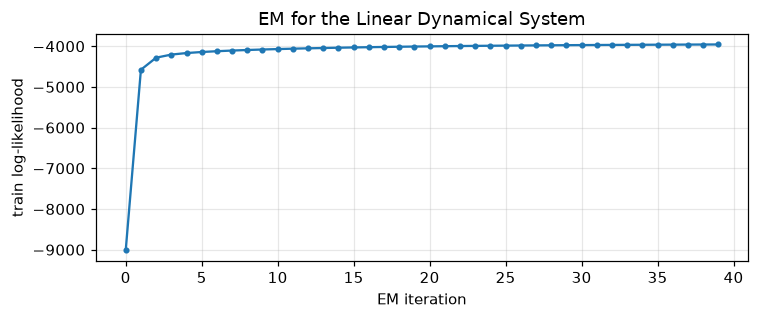

In [18]:
def lds_obs(df):
    return np.column_stack([np.log(df['pkt_rate'].values), np.log(df['avg_pkt_size'].values)])

def kalman_filter(X, A, C, Q, R, mu0, V0):
    N, L = len(X), len(mu0); I = np.eye(L)
    mu = np.zeros((N, L)); V = np.zeros((N, L, L))
    m_pred = np.zeros((N, L)); P_pred = np.zeros((N, L, L)); ll = 0.0
    for n in range(N):
        mp, Pp = (mu0, V0) if n == 0 else (A @ mu[n - 1], A @ V[n - 1] @ A.T + Q)
        S = C @ Pp @ C.T + R
        Kg = Pp @ C.T @ np.linalg.inv(S)
        innov = X[n] - C @ mp
        mu[n] = mp + Kg @ innov
        V[n] = (I - Kg @ C) @ Pp
        m_pred[n], P_pred[n] = mp, Pp
        ll += multivariate_normal.logpdf(innov, mean=np.zeros(len(innov)), cov=S)
    return mu, V, m_pred, P_pred, ll

def rts_smoother(A, Q, mu, V):
    N, L = mu.shape
    mu_s, V_s, J = mu.copy(), V.copy(), np.zeros((N, L, L))
    for n in range(N - 2, -1, -1):
        P = A @ V[n] @ A.T + Q
        J[n] = V[n] @ A.T @ np.linalg.inv(P)
        mu_s[n] = mu[n] + J[n] @ (mu_s[n + 1] - A @ mu[n])
        V_s[n] = V[n] + J[n] @ (V_s[n + 1] - P) @ J[n].T
    return mu_s, V_s, J

def lds_em(X_list, A, C, Q, R, mu0, V0, n_iter=40):
    L, history = len(mu0), []
    for it in range(n_iter):
        S_zz_prev = np.zeros((L, L)); S_zz_lag = np.zeros((L, L)); S_zz_curr = np.zeros((L, L))
        S_xx = 0; S_xz = 0; S_zz_all = 0; Ez1 = []; Ez1z1 = []; n_trans = 0; n_obs = 0; ll_tot = 0
        for X in X_list:                                           # E-step
            mu, V, _, _, ll = kalman_filter(X, A, C, Q, R, mu0, V0)
            mu_s, V_s, J = rts_smoother(A, Q, mu, V)
            ll_tot += ll
            Ezz = V_s + np.einsum('ni,nj->nij', mu_s, mu_s)                    # E[z_n z_n^T]
            Ezz_lag = np.einsum('nij,nkj->nik', V_s[1:], J[:-1]) + \
                      np.einsum('ni,nj->nij', mu_s[1:], mu_s[:-1])             # E[z_n z_{n-1}^T]
            S_zz_lag += Ezz_lag.sum(0); S_zz_prev += Ezz[:-1].sum(0); S_zz_curr += Ezz[1:].sum(0)
            S_xx = S_xx + X.T @ X; S_xz = S_xz + X.T @ mu_s; S_zz_all = S_zz_all + Ezz.sum(0)
            Ez1.append(mu_s[0]); Ez1z1.append(Ezz[0]); n_trans += len(X) - 1; n_obs += len(X)
        history.append(ll_tot)
        A = S_zz_lag @ np.linalg.inv(S_zz_prev)                    # M-step
        Q = (S_zz_curr - A @ S_zz_lag.T - S_zz_lag @ A.T + A @ S_zz_prev @ A.T) / n_trans
        Q = (Q + Q.T) / 2 + 1e-8 * np.eye(L)
        R = (S_xx - C @ S_xz.T - S_xz @ C.T + C @ S_zz_all @ C.T) / n_obs
        R = (R + R.T) / 2 + 1e-8 * np.eye(len(R))
        mu0 = np.mean(Ez1, 0)
        V0 = np.mean(Ez1z1, 0) - np.outer(mu0, mu0) + 1e-3 * np.eye(L)
    return A, Q, R, mu0, V0, history

# initial local-linear-trend model: state = [level_rate, trend_rate, level_size, trend_size]
LLT = np.array([[1., 1.], [0., 1.]])
A0 = np.block([[LLT, np.zeros((2, 2))], [np.zeros((2, 2)), LLT]])
C_lds = np.array([[1., 0., 0., 0.], [0., 0., 1., 0.]])
Q0, R0 = np.eye(4) * 0.01, np.eye(2) * 0.05

X_lds_train = [lds_obs(s) for s in train_sessions[:8]]
X_lds_test = [lds_obs(s) for s in test_sessions]
mu00 = np.array([X_lds_train[0][0, 0], 0., X_lds_train[0][0, 1], 0.])
V00 = np.eye(4)

A_lds, Q_lds, R_lds, mu0_lds, V0_lds, hist_lds = lds_em(X_lds_train, A0, C_lds, Q0, R0, mu00, V00, n_iter=40)
print(f"LDS EM: log-likelihood {hist_lds[0]:.1f} -> {hist_lds[-1]:.1f} over {len(hist_lds)} iterations")
print("Monotone increase:", np.all(np.diff(hist_lds) > -1e-6))
print("\nLearned transition matrix A:\n", A_lds)
print("\nLearned process noise Gamma (diag):", np.diag(Q_lds))
print("Learned observation noise Sigma (diag):", np.diag(R_lds))
plt.figure(figsize=(7, 3)); plt.plot(hist_lds, 'o-', ms=3)
plt.xlabel('EM iteration'); plt.ylabel('train log-likelihood'); plt.title('EM for the Linear Dynamical System')
plt.tight_layout(); plt.show()

### 5.1 Tracking traffic characteristics and one-step-ahead prediction
For each test window, the model predicts the next observation from data up to the previous window, $\mathbb E[\mathbf x_n\mid\mathbf x_{1:n-1}]=\mathbf C\mathbf A\boldsymbol\mu_{n-1}$. This is compared with two naive forecasters: *persistence* ($\hat{\mathbf x}_n=\mathbf x_{n-1}$) and a *1-hour moving average*.

In [19]:
rmse = lambda e: np.sqrt(np.mean(e ** 2, axis=0))
err_kf, err_persist, err_ma = [], [], []
for X in X_lds_test:
    _, _, m_pred, _, _ = kalman_filter(X, A_lds, C_lds, Q_lds, R_lds, mu0_lds, V0_lds)
    pred = m_pred @ C_lds.T
    err_kf.append(X[13:] - pred[13:])
    err_persist.append(X[13:] - X[12:-1])
    ma = np.array([X[n - 12:n].mean(0) for n in range(13, len(X))])
    err_ma.append(X[13:] - ma)
tbl = pd.DataFrame([rmse(np.vstack(e)) for e in (err_kf, err_persist, err_ma)],
                   index=['LDS / Kalman one-step prediction', 'Persistence (last value)', '1-hour moving average'],
                   columns=['RMSE log pkt_rate', 'RMSE log avg_pkt_size'])
tbl['Improvement vs persistence (rate)'] = (1 - tbl.iloc[:, 0] / tbl.iloc[1, 0]).map('{:.1%}'.format)
tbl

,RMSE log pkt_rate,RMSE log avg_pkt_size,Improvement vs persistence (rate)
LDS / Kalman one-step prediction,0.425,0.405,12.9%
Persistence (last value),0.489,0.462,0.0%
1-hour moving average,0.516,0.501,-5.6%


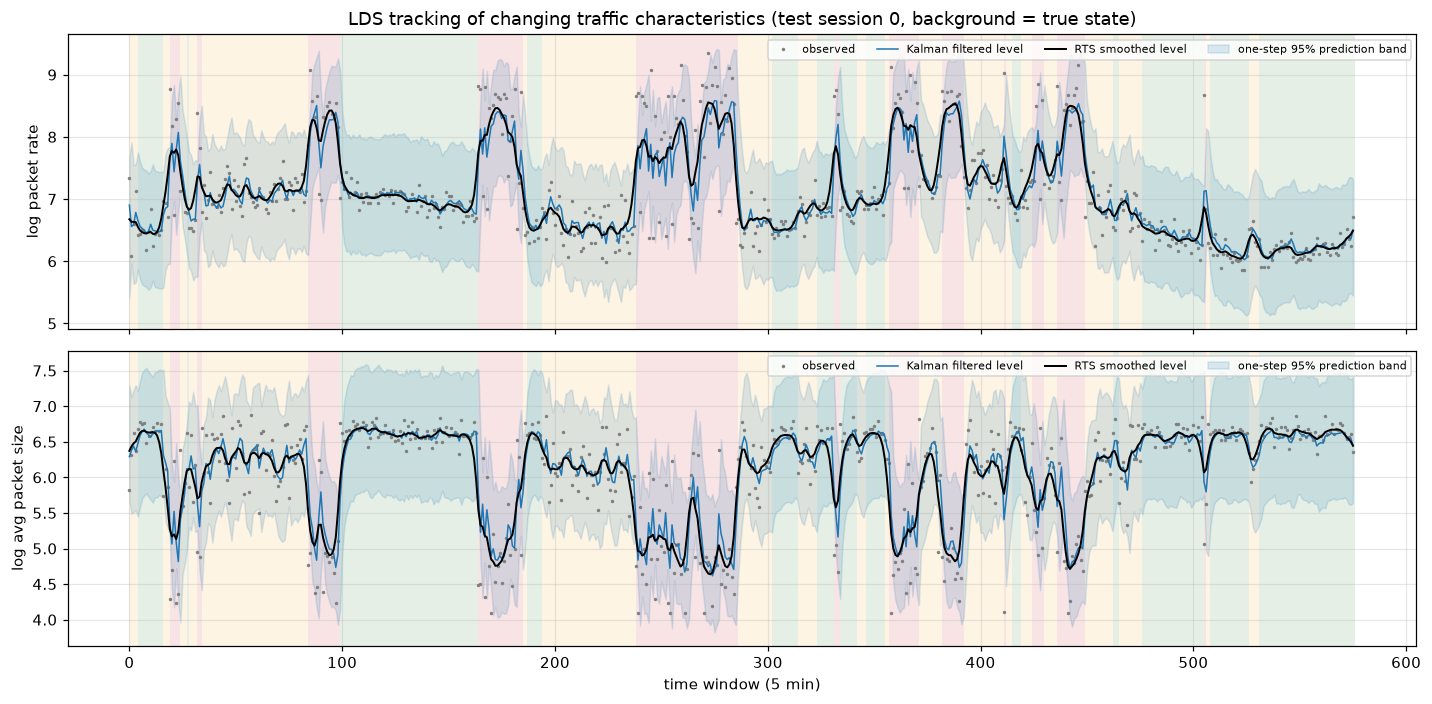

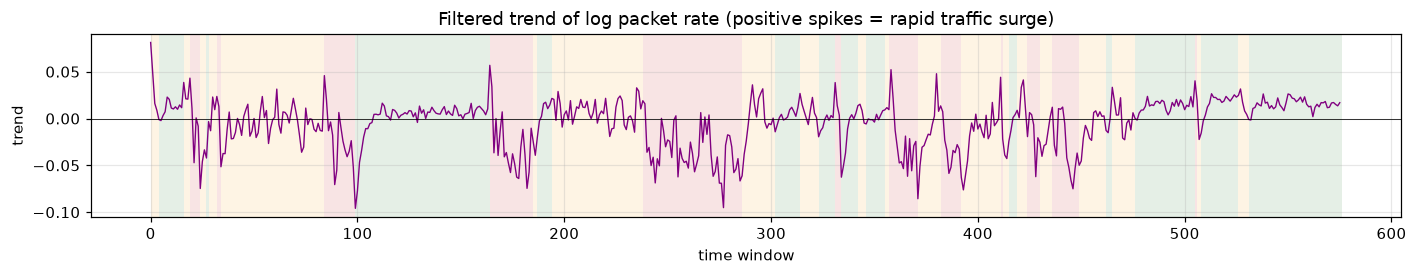

In [20]:
X, z = X_lds_test[0], Ztest[0]
mu_f, V_f, m_pred, P_pred, _ = kalman_filter(X, A_lds, C_lds, Q_lds, R_lds, mu0_lds, V0_lds)
mu_s, V_s, _ = rts_smoother(A_lds, Q_lds, mu_f, V_f)
pred = m_pred @ C_lds.T
pred_sd = np.sqrt(np.array([np.diag(C_lds @ P @ C_lds.T + R_lds) for P in P_pred]))

fig, ax = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True)
for d, (a, lab) in enumerate(zip(ax, ['log packet rate', 'log avg packet size'])):
    shade_states(a, z, alpha=0.12)
    a.plot(X[:, d], '.', ms=2.5, color='grey', label='observed')
    a.plot((mu_f @ C_lds.T)[:, d], lw=1, color='tab:blue', label='Kalman filtered level')
    a.plot((mu_s @ C_lds.T)[:, d], lw=1.3, color='k', label='RTS smoothed level')
    a.fill_between(range(len(X)), pred[:, d] - 2 * pred_sd[:, d], pred[:, d] + 2 * pred_sd[:, d],
                   color='tab:blue', alpha=0.15, label='one-step 95% prediction band')
    a.set_ylabel(lab); a.legend(loc='upper right', fontsize=7, ncol=4)
ax[0].set_title('LDS tracking of changing traffic characteristics (test session 0, background = true state)')
ax[1].set_xlabel('time window (5 min)'); plt.tight_layout(); plt.show()

# the trend component reveals sudden changes in traffic volume
fig, a = plt.subplots(figsize=(13, 2.6))
shade_states(a, z, alpha=0.12)
a.plot(mu_f[:, 1], lw=0.9, color='purple'); a.axhline(0, color='k', lw=0.5)
a.set(title='Filtered trend of log packet rate (positive spikes = rapid traffic surge)', xlabel='time window', ylabel='trend')
plt.tight_layout(); plt.show()

### 5.2 Predicting future traffic conditions
**Multi-step LDS forecast.** From the filtered state at window $n_0$, the $h$-step-ahead predictive distribution is Gaussian:
$$\mathbb E[\mathbf x_{n_0+h}]=\mathbf C\mathbf A^h\boldsymbol\mu_{n_0},\qquad \mathrm{Cov}[\mathbf x_{n_0+h}]=\mathbf C\left(\mathbf A^h\mathbf V_{n_0}\mathbf A^{h\top}+\sum_{j=0}^{h-1}\mathbf A^j\boldsymbol\Gamma\mathbf A^{j\top}\right)\mathbf C^\top+\boldsymbol\Sigma.$$

**HMM forecast of the security state.** The HMM can also forecast the *discrete* network condition: $p(z_{n_0+h}\mid x_{1:n_0})=\hat\alpha(z_{n_0})^\top\mathbf A^h$, giving the probability that the network will be under attack in the next few hours.

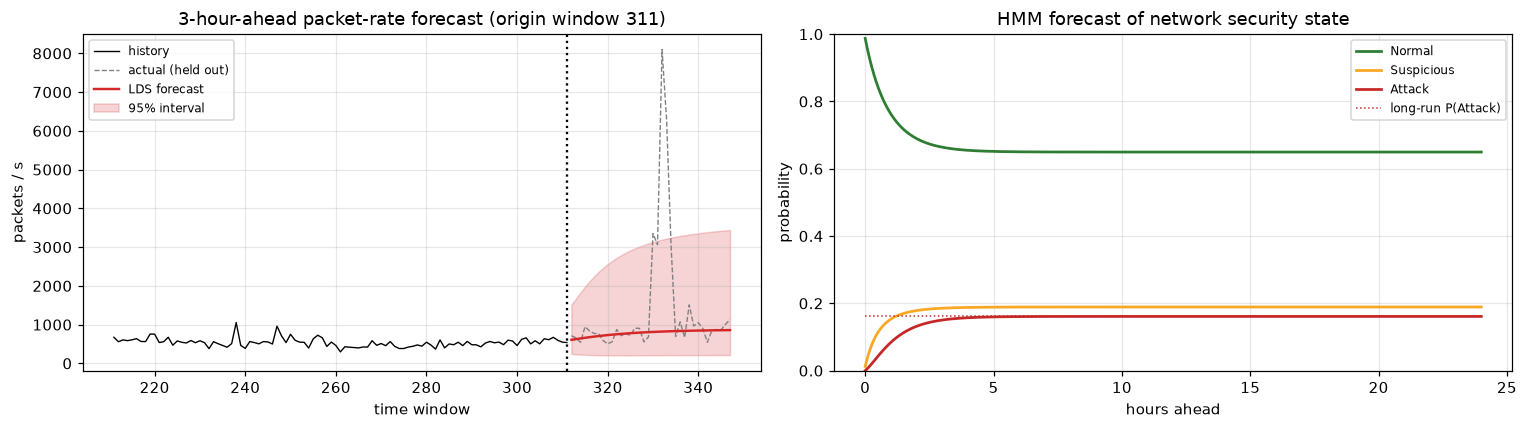

92% of the held-out packet-rate values fall inside the LDS 95% forecast interval.
P(Attack)   5 min ahead = 0.0060
P(Attack)  30 min ahead = 0.0431
P(Attack)  60 min ahead = 0.0841
P(Attack) 180 min ahead = 0.1504


In [21]:
def lds_forecast(mu_n, V_n, A, C, Q, R, H):
    means, sds = [], []
    m, P = mu_n.copy(), V_n.copy()
    for h in range(1, H + 1):
        m = A @ m; P = A @ P @ A.T + Q
        means.append(C @ m); sds.append(np.sqrt(np.diag(C @ P @ C.T + R)))
    return np.array(means), np.array(sds)

# pick a test session and a forecast origin during normal traffic
X = X_lds_test[1]; z = Ztest[1]
cands = [n for n in range(150, len(X) - 40) if np.all(z[n - 12:n + 1] == 0)]
n0, H = cands[len(cands) // 2], 36
mu_f, V_f, _, _, _ = kalman_filter(X[:n0 + 1], A_lds, C_lds, Q_lds, R_lds, mu0_lds, V0_lds)
fm, fsd = lds_forecast(mu_f[-1], V_f[-1], A_lds, C_lds, Q_lds, R_lds, H)
hz = np.arange(n0 + 1, n0 + 1 + H)
actual = X[n0 + 1:n0 + 1 + H, 0]
inside = np.mean(np.abs(actual - fm[:, 0]) <= 1.96 * fsd[:, 0])

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
lo = n0 - 100
ax[0].plot(range(lo, n0 + 1), np.exp(X[lo:n0 + 1, 0]), color='k', lw=0.9, label='history')
ax[0].plot(hz, np.exp(actual), color='grey', lw=0.9, ls='--', label='actual (held out)')
ax[0].plot(hz, np.exp(fm[:, 0]), color='tab:red', lw=1.6, label='LDS forecast')
ax[0].fill_between(hz, np.exp(fm[:, 0] - 1.96 * fsd[:, 0]), np.exp(fm[:, 0] + 1.96 * fsd[:, 0]),
                   color='tab:red', alpha=0.2, label='95% interval')
ax[0].axvline(n0, color='k', ls=':'); ax[0].set(title=f'3-hour-ahead packet-rate forecast (origin window {n0})',
                                              xlabel='time window', ylabel='packets / s')
ax[0].legend(fontsize=8)

# HMM state forecast from the same origin
a_hat, _ = forward_scaled(Xtest[1][:n0 + 1], pi_hat, A_hat, B_hat)
p_future = np.array([a_hat[-1] @ np.linalg.matrix_power(A_hat, h) for h in range(0, 289)])
for k in range(K):
    ax[1].plot(np.arange(289) * 5 / 60, p_future[:, k], color=STATE_COLORS[k], lw=1.8, label=STATES[k])
ax[1].plot(np.arange(289) * 5 / 60, np.tile(pi_stat, (289, 1))[:, 2], color=STATE_COLORS[2], ls=':', lw=1,
           label='long-run P(Attack)')
ax[1].set(title='HMM forecast of network security state', xlabel='hours ahead', ylabel='probability', ylim=(0, 1))
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

print(f"{100 * inside:.0f}% of the held-out packet-rate values fall inside the LDS 95% forecast interval.")
for h in (1, 6, 12, 36):
    print(f"P(Attack) {h * 5:>3} min ahead = {p_future[h, 2]:.4f}")

**Interpretation.** During normal operation the LDS forecast follows the slowly changing load, and its uncertainty band widens with the horizon as expected. If an attack begins inside the forecast window, the resulting surge falls outside the band: a single linear-Gaussian model assumes smooth dynamics and cannot anticipate abrupt regime changes. That is exactly the gap the HMM fills. Its state forecast quantifies the growing probability that the network will move into the Suspicious or Attack regime, converging to the long-run (stationary) risk after a few hours. Used together, the LDS describes *how much* traffic to expect and the HMM describes *what kind* of traffic condition to expect.

## 6. Summary of results

In [22]:
summary = pd.DataFrame([
    ['1', 'Markov chain over 8 traffic conditions',
     f"Test perplexity {np.exp(-ll_mc):.2f} vs {np.exp(-ll_iid):.2f} for i.i.d. model"],
    ['2', 'HMM (Normal/Suspicious/Attack), supervised MLE',
     f"max |A_hat - A_true| = {np.abs(A_hat - A_TRUE).max():.3f}"],
    ['3', 'Forward / Backward / Sum-Product',
     'p(X) matches brute force; sum-product marginals = forward-backward gamma, xi'],
    ['4', 'Scaling + Viterbi',
     f"Unscaled underflows at n={first_zero}; scaled log p(X) exact; Viterbi accuracy "
     f"{accuracy_score(y_true, y_vit):.3f} vs baseline {accuracy_score(y_true, y_base):.3f}"],
    ['4+', 'Baum-Welch (unsupervised MLE)', f"Viterbi accuracy without labels: {em_results[3]['acc']:.3f} with K=3, {em_results[4]['acc']:.3f} with K=4"],
    ['4+', 'Online attack detector', f"{detected}/{n_eps} attack episodes detected, mean delay {5 * np.mean(delays):.1f} min"],
    ['5', 'Linear Dynamical System (Kalman + RTS + EM)',
     f"1-step RMSE (log rate) {tbl.iloc[0, 0]:.3f} vs persistence {tbl.iloc[1, 0]:.3f}; "
     f"{100 * inside:.0f}% of 3-h forecast inside 95% band"],
], columns=['Task', 'Method', 'Key result'])
summary.style.hide(axis='index').set_properties(**{'text-align': 'left'})

Task,Method,Key result
1,Markov chain over 8 traffic conditions,Test perplexity 4.50 vs 7.50 for i.i.d. model
2,"HMM (Normal/Suspicious/Attack), supervised MLE",max |A_hat - A_true| = 0.005
3,Forward / Backward / Sum-Product,"p(X) matches brute force; sum-product marginals = forward-backward gamma, xi"
4,Scaling + Viterbi,Unscaled underflows at n=478; scaled log p(X) exact; Viterbi accuracy 0.981 vs baseline 0.927
4+,Baum-Welch (unsupervised MLE),"Viterbi accuracy without labels: 0.828 with K=3, 0.973 with K=4"
4+,Online attack detector,"83/84 attack episodes detected, mean delay 0.8 min"
5,Linear Dynamical System (Kalman + RTS + EM),1-step RMSE (log rate) 0.425 vs persistence 0.489; 92% of 3-h forecast inside 95% band


### Conclusions
1. Network traffic windows are strongly sequentially dependent: a first-order Markov chain over traffic conditions beats an independent model.
2. An HMM with hidden states **Normal / Suspicious / Attack** captures the latent security condition; its MLE parameters recover the true dynamics closely.
3. Forward-Backward and Sum-Product produce identical likelihoods and posteriors (the forward and backward variables are the sum-product messages), verified against brute-force enumeration.
4. Scaling is essential for realistic sequence lengths; with it, exact log-likelihoods are obtained. Viterbi decoding exploits temporal persistence to recover stealthy scans and pulsing attacks that a per-window classifier misses, and the filtered posterior gives a practical real-time alarm.
5. The LDS tracks the continuously changing traffic level and trend, beats naive forecasters for one-step prediction, and provides calibrated multi-step forecasts; together with the HMM's state forecast it predicts future traffic conditions.

**Limitations and future work:** emissions are discretised by k-means (a Gaussian-emission HMM would use the continuous features directly); the HMM and LDS are separate models, and could be unified in a *switching* LDS where each hidden security state has its own dynamics; validation on a real labelled dataset (e.g. CIC-IDS2017 aggregated into time windows) is the natural next step.